In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score

In [2]:
df = pd.read_csv('Salary_Data.csv')  # or the correct filename
x = df[['YearsExperience']].values
y = df['Salary'].values

In [5]:
# degree 1
poly1 = PolynomialFeatures(degree=1, include_bias=False)
x1 = poly1.fit_transform(x)
model1 = LinearRegression()
model1.fit(x1, y)
y1 = model1.predict(x1)
print('Degree 1 R2:', round(r2_score(y, y1),4))

# degree 2
poly2 = PolynomialFeatures(degree=2, include_bias=False)
x2 = poly2.fit_transform(x)
model2 = LinearRegression()
model2.fit(x2, y)
y2 = model2.predict(x2)
print('Degree 2 R2:', round(r2_score(y, y2),4))

# degree 3
poly3 = PolynomialFeatures(degree=3, include_bias=False)
x3 = poly3.fit_transform(x)
model3 = LinearRegression()
model3.fit(x3, y)
y3 = model3.predict(x3)
print('Degree 3 R2:',round( r2_score(y, y3),4))

# degree 4
poly4 = PolynomialFeatures(degree=4, include_bias=False)
x4 = poly4.fit_transform(x)
model4 = LinearRegression()
model4.fit(x4, y)
y4 = model4.predict(x4)
print('Degree 4 R2:', round(r2_score(y, y4),4))

# degree 5
poly5 = PolynomialFeatures(degree=5, include_bias=False)
x5 = poly5.fit_transform(x)
model5 = LinearRegression()
model5.fit(x5, y)
y5 = model5.predict(x5)
print('Degree 5 R2:', round(r2_score(y, y5),4))

# degree 10
poly10 = PolynomialFeatures(degree=10, include_bias=False)
x10 = poly10.fit_transform(x)
model10 = LinearRegression()
model10.fit(x10, y)
y10 = model10.predict(x10)
print('Degree 10 R2:', round(r2_score(y, y10),4))

# degree 20
poly20 = PolynomialFeatures(degree=20, include_bias=False)
x20 = poly20.fit_transform(x)
model20 = LinearRegression()
model20.fit(x20, y)
y20 = model20.predict(x20)
print('Degree 20 R2:', round(r2_score(y, y20),4))

# degree 30
poly30 = PolynomialFeatures(degree=30, include_bias=False)
x30 = poly30.fit_transform(x)
model30 = LinearRegression()
model30.fit(x30, y)
y30 = model30.predict(x30)
print('Degree 30 R2:', round(r2_score(y, y30),4))

Degree 1 R2: 0.957
Degree 2 R2: 0.957
Degree 3 R2: 0.9636
Degree 4 R2: 0.9637
Degree 5 R2: 0.9644
Degree 10 R2: 0.9494
Degree 20 R2: 0.6368
Degree 30 R2: 0.5001


Degree 1: R2 = 0.9570
Degree 2: R2 = 0.9570
Degree 3: R2 = 0.9636
Degree 4: R2 = 0.9637
Degree 5: R2 = 0.9644


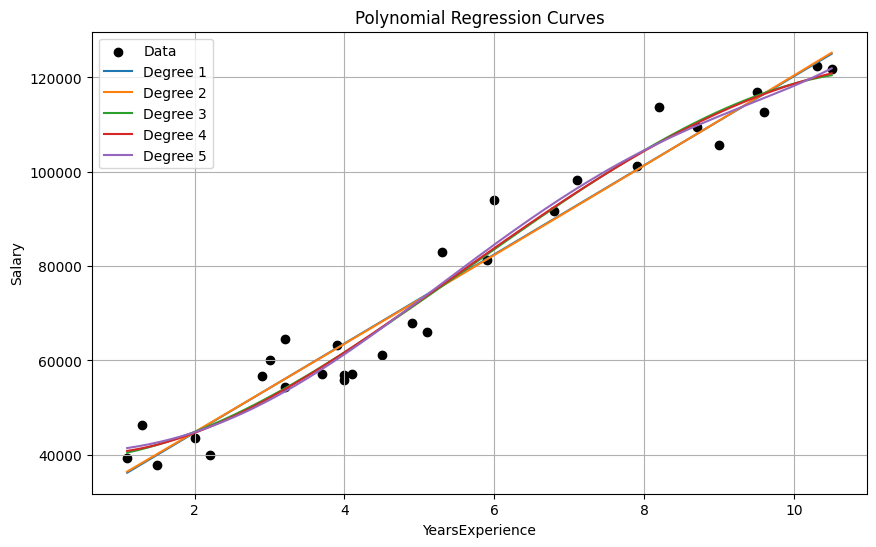

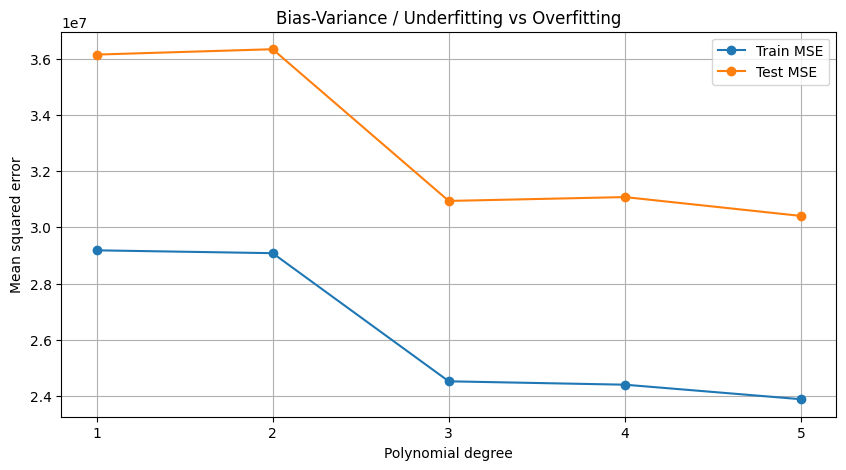

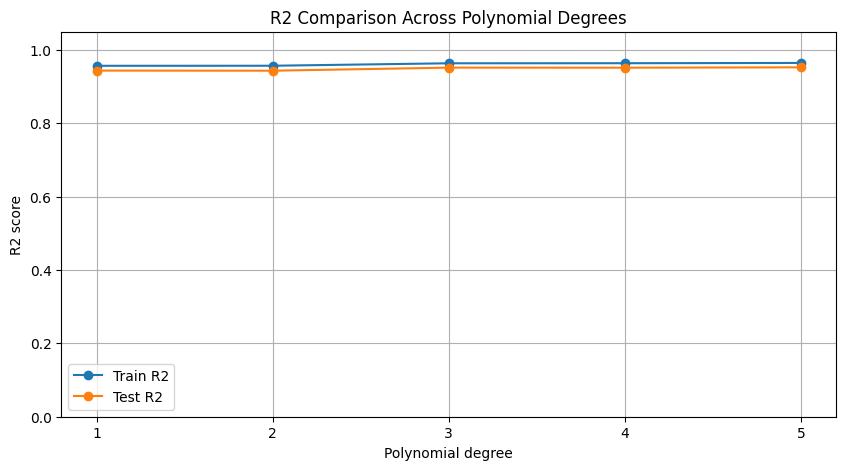

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

degrees = [1, 2, 3, 4, 5]
x_plot = np.linspace(x.min(), x.max(), 200).reshape(-1, 1)

plt.figure(figsize=(10, 6))
plt.scatter(x, y, color='black', label='Data')

train_r2 = []
test_r2 = []
train_mse = []
test_mse = []

for d in degrees:
    poly = PolynomialFeatures(degree=d, include_bias=False)
    x_d = poly.fit_transform(x)

    model = LinearRegression()
    model.fit(x_d, y)

    y_pred = model.predict(x_d)
    print(f'Degree {d}: R2 = {r2_score(y, y_pred):.4f}')

    plt.plot(x_plot, model.predict(poly.transform(x_plot)), label=f'Degree {d}')

    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)
    x_train_d = poly.transform(x_train)
    x_test_d = poly.transform(x_test)

    y_train_pred = model.predict(x_train_d)
    y_test_pred = model.predict(x_test_d)

    train_r2.append(r2_score(y_train, y_train_pred))
    test_r2.append(r2_score(y_test, y_test_pred))
    train_mse.append(mean_squared_error(y_train, y_train_pred))
    test_mse.append(mean_squared_error(y_test, y_test_pred))

plt.xlabel('YearsExperience')
plt.ylabel('Salary')
plt.title('Polynomial Regression Curves')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(degrees, train_mse, marker='o', label='Train MSE')
plt.plot(degrees, test_mse, marker='o', label='Test MSE')
plt.xlabel('Polynomial degree')
plt.ylabel('Mean squared error')
plt.title('Bias-Variance / Underfitting vs Overfitting')
plt.xticks(degrees)
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(degrees, train_r2, marker='o', label='Train R2')
plt.plot(degrees, test_r2, marker='o', label='Test R2')
plt.xlabel('Polynomial degree')
plt.ylabel('R2 score')
plt.title('R2 Comparison Across Polynomial Degrees')
plt.xticks(degrees)
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.show()